In [1]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as z:
    z.extractall("data")
    print(z.namelist())   # andar ki files ke naam dikhayega

['cardekho.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/cardekho.csv")

print(df.shape)
df.head()

(8128, 12)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [3]:
df.info()
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.1+ KB
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type  

,year,selling_price,km_driven,mileage(km/ltr/kg),engine,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000,7907.000000,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,19.418783,1458.625016,5.416719
std,4.044249,8.062534e+05,5.655055e+04,4.037145,503.916303,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,16.780000,1197.000000,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,19.300000,1248.000000,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,22.320000,1582.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,14.000000


In [4]:
# 1. Column ka naam chhota karo
df = df.rename(columns={'mileage(km/ltr/kg)': 'mileage'})

# 2. Duplicates hatao
df = df.drop_duplicates()

# 3. max_power ko number banao
df['max_power'] = pd.to_numeric(df['max_power'], errors='coerce')

# 4. Missing values wali rows hatao
df = df.dropna()

# 5. Galat values hatao
df = df[df['mileage'] > 0]
df = df[df['km_driven'] < df['km_driven'].quantile(0.99)]
df = df[df['selling_price'] < df['selling_price'].quantile(0.99)]

# 6. Naye columns banao
df['car_age'] = 2026 - df['year']
df['brand'] = df['name'].str.split().str[0]

print(df.shape)
print(df.isnull().sum().sum())   # 0 aana chahiye

(6567, 14)
0


In [5]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

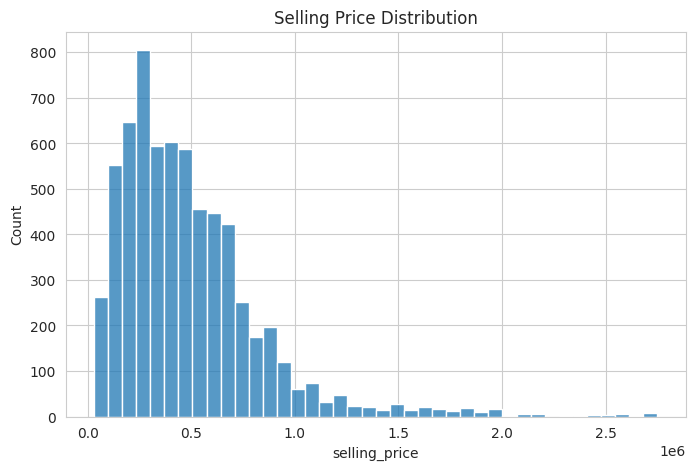

In [6]:
sns.histplot(df['selling_price'], bins=40)
plt.title("Selling Price Distribution")
plt.show()

Insight: The price distribution is right-skewed. Most used cars are priced in the lower range (a few lakh rupees), while only a small number of premium cars are very expensive. Because of this skew, the median is a better measure of a “typical” price than the mean.

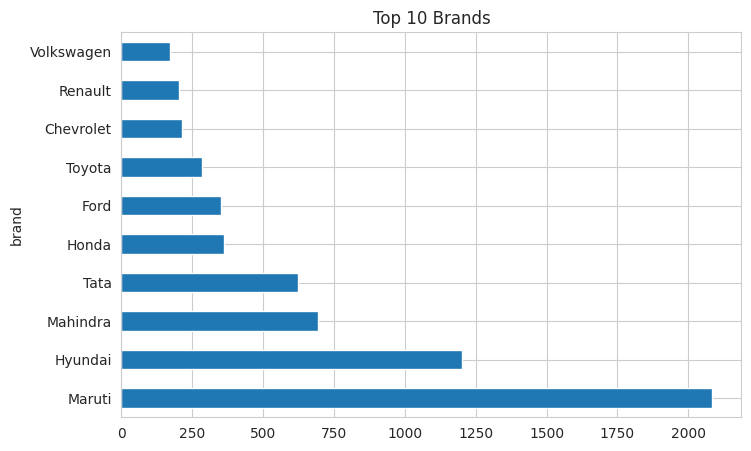

In [7]:
df['brand'].value_counts().head(10).plot(kind='barh')
plt.title("Top 10 Brands")
plt.show()

Insight: The market is dominated by a few brands, with Maruti leading by a wide margin, followed by Hyundai, Mahindra, Tata and Honda. This suggests that budget-friendly, widely available brands account for most used car listings.

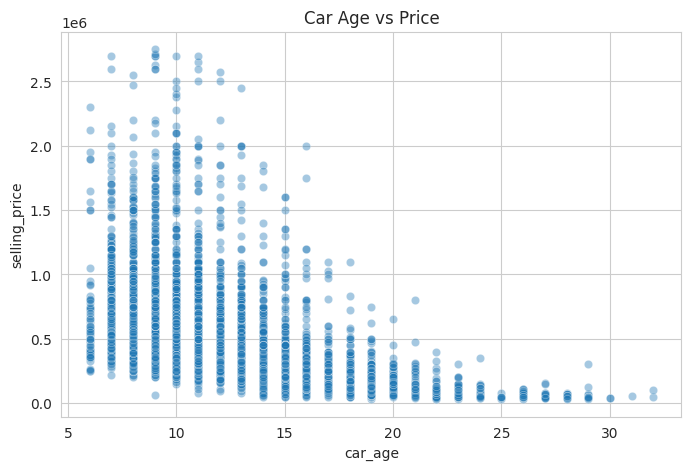

In [8]:
sns.scatterplot(x='car_age', y='selling_price', data=df, alpha=0.4)
plt.title("Car Age vs Price")
plt.show()

Insight: There is a clear negative relationship between car age and price: newer cars sell for more. The drop is steepest in the first few years, and the price curve flattens for older cars. High-priced cars are almost all less than 10 years old.

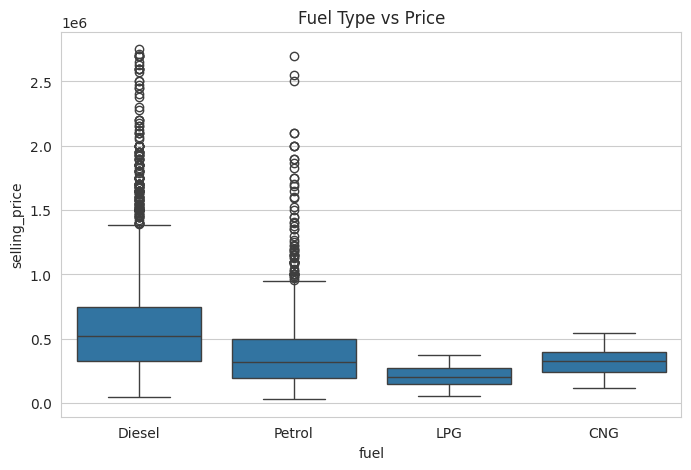

In [9]:
sns.boxplot(x='fuel', y='selling_price', data=df)
plt.title("Fuel Type vs Price")
plt.show()

Insight: Diesel cars generally have a higher median price than petrol cars, likely because diesel models tend to be larger vehicles such as SUVs. CNG and LPG cars are usually cheaper and fewer in number, so conclusions about them are less reliable.

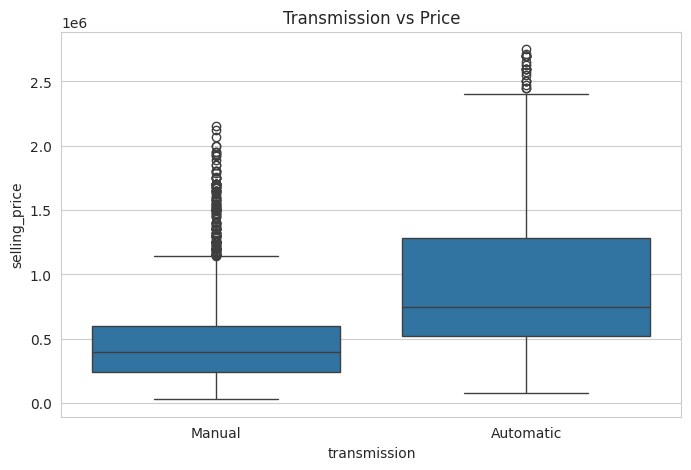

In [10]:
sns.boxplot(x='transmission', y='selling_price', data=df)
plt.title("Transmission vs Price")
plt.show()

Insight: Automatic cars have a noticeably higher median price than manual cars. Manual cars are far more common, but automatics are concentrated in the mid-to-premium range.

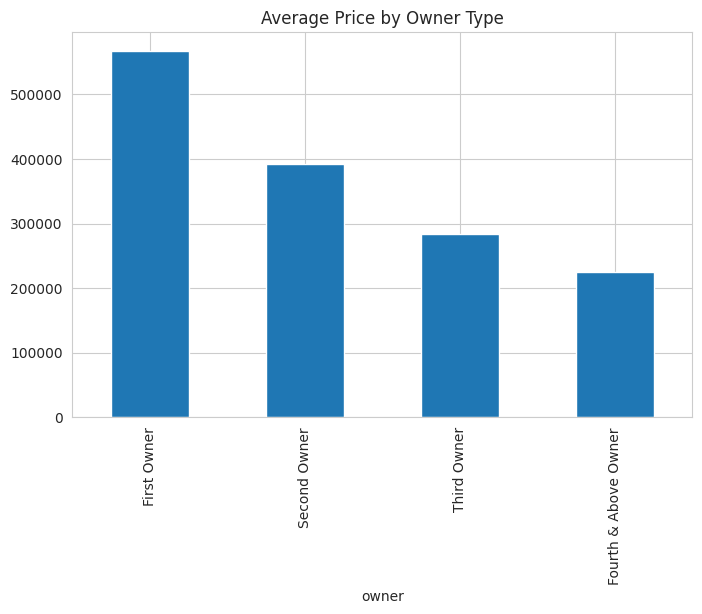

In [11]:
order = ['First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner']
df.groupby('owner')['selling_price'].mean().reindex(order).plot(kind='bar')
plt.title("Average Price by Owner Type")
plt.show()

Insight: Average price falls as the number of previous owners increases. First-owner cars command the highest prices, which shows that buyers value a car with fewer previous owners.

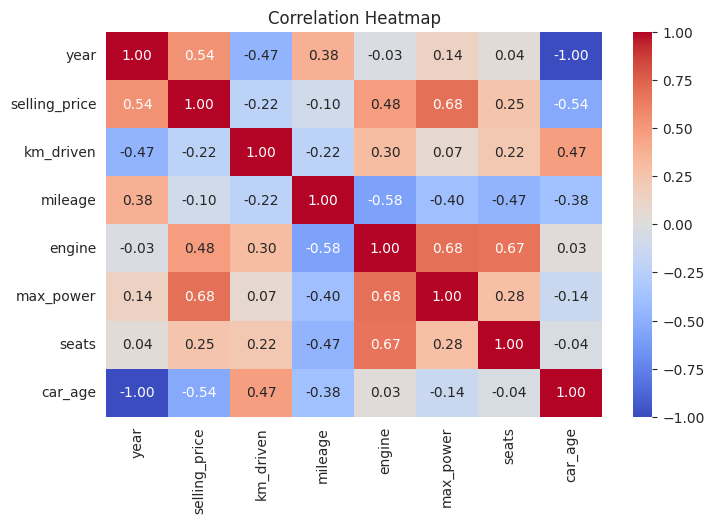

In [12]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

Insight: max_power and engine show the strongest positive correlation with selling price, meaning more powerful cars cost more. car_age and km_driven are negatively related to price. max_power and engine are also strongly correlated with each other, so they carry overlapping information.

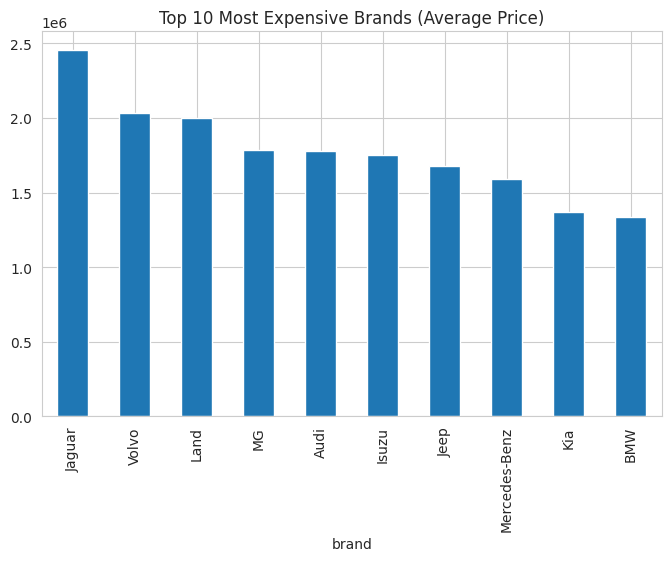

In [13]:
df.groupby('brand')['selling_price'].mean().sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("Top 10 Most Expensive Brands (Average Price)")
plt.show()

Insight: Luxury brands such as Mercedes-Benz, BMW and Audi have the highest average prices, far above mass-market brands. Brand is clearly a strong predictor of price and should be included as a feature in the model.

In [14]:
print("Median price by fuel:\n", df.groupby('fuel')['selling_price'].median(), "\n")
print("Median price by transmission:\n", df.groupby('transmission')['selling_price'].median(), "\n")
print("Correlation with price:\n", df.corr(numeric_only=True)['selling_price'].sort_values(ascending=False))

Median price by fuel:
 fuel
CNG       330000.0
Diesel    522000.0
LPG       200000.0
Petrol    320000.0
Name: selling_price, dtype: float64 

Median price by transmission:
 transmission
Automatic    750000.0
Manual       400000.0
Name: selling_price, dtype: float64 

Correlation with price:
 selling_price    1.000000
max_power        0.681235
year             0.536027
engine           0.481620
seats            0.254820
mileage         -0.096528
km_driven       -0.222601
car_age         -0.536027
Name: selling_price, dtype: float64


In [15]:
# Model ko 'name' aur 'year' nahi chahiye (brand aur car_age already hain)
df_model = df.drop(columns=['name', 'year'])

# Text columns (fuel, owner, brand...) ko 0/1 columns mein badlo
df_encoded = pd.get_dummies(df_model, drop_first=True)

X = df_encoded.drop('selling_price', axis=1)   # inputs
y = df_encoded['selling_price']                # jo predict karna hai

print(X.shape)

(6567, 45)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(5253, 45) (1314, 45)


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

print("Linear Regression R2 :", round(r2_score(y_test, lr_pred), 3))
print("Linear Regression MAE:", round(mean_absolute_error(y_test, lr_pred)))

Linear Regression R2 : 0.812
Linear Regression MAE: 106320


In [18]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random Forest R2 :", round(r2_score(y_test, rf_pred), 3))
print("Random Forest MAE:", round(mean_absolute_error(y_test, rf_pred)))

Random Forest R2 : 0.904
Random Forest MAE: 70269


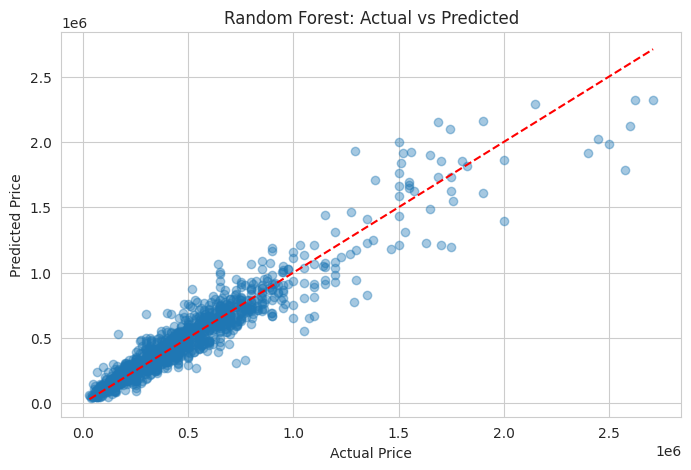

In [19]:
plt.scatter(y_test, rf_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

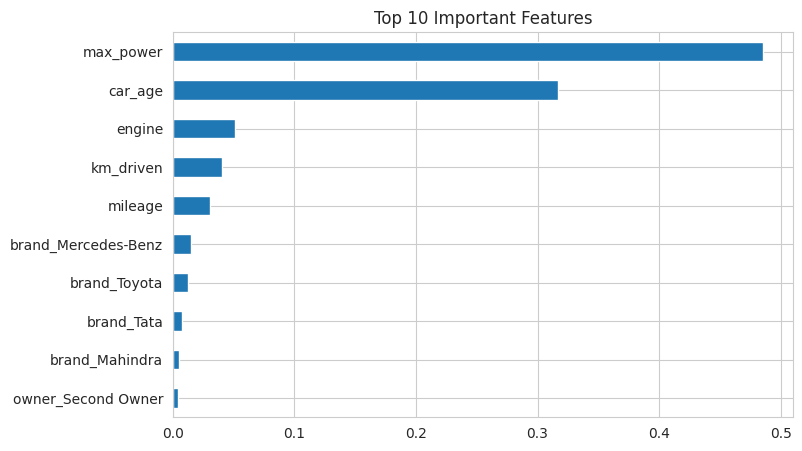

In [20]:
imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(10)
imp.sort_values().plot(kind='barh')
plt.title("Top 10 Important Features")
plt.show()

In [21]:
y_train_log = np.log1p(y_train)

rf_log = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_log.fit(X_train, y_train_log)

rf_log_pred = np.expm1(rf_log.predict(X_test))   # wapas rupaye mein badlo

print("RF (log) R2 :", round(r2_score(y_test, rf_log_pred), 3))
print("RF (log) MAE:", round(mean_absolute_error(y_test, rf_log_pred)))

RF (log) R2 : 0.909
RF (log) MAE: 68296


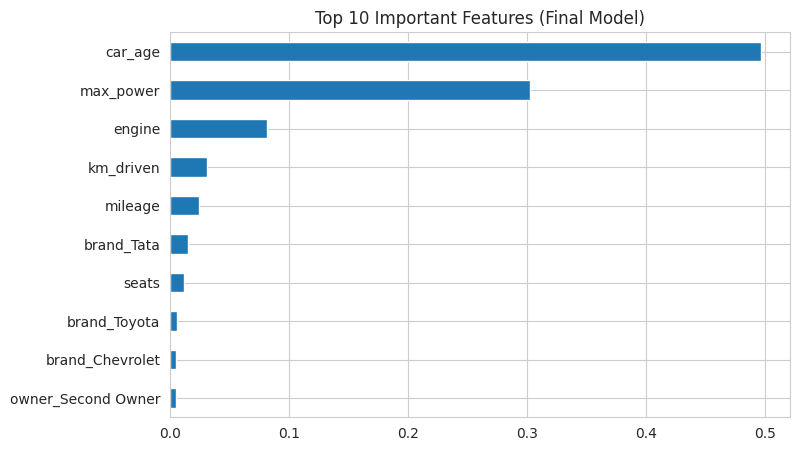

car_age               0.496045
max_power             0.302617
engine                0.081026
km_driven             0.031131
mileage               0.023908
brand_Tata            0.014662
seats                 0.011682
brand_Toyota          0.005407
brand_Chevrolet       0.005079
owner_Second Owner    0.004841
dtype: float64


In [22]:
imp = pd.Series(rf_log.feature_importances_, index=X.columns).nlargest(10)
imp.sort_values().plot(kind='barh')
plt.title("Top 10 Important Features (Final Model)")
plt.show()

print(imp)